In [1]:
import pandas as pd
import numpy as np


In [2]:
!curl -L -o data-week4.csv https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  272k  100  272k    0     0   366k      0 --:--:-- --:--:-- --:--:--  366k   0     0      0      0 --:--:-- --:--:-- --:--:--     0


In [3]:

df = pd.read_csv("data-week4.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [12]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [18]:
categorical = df.select_dtypes(include=['object', 'string', 'category']).columns.tolist()

In [19]:
categorical

['lead_source', 'industry', 'employment_status', 'location']

In [16]:
##Look at the fuel_efficiency_mpg variable. Does it have a long tail?
# no long tail. its a clean normal bell curve

In [20]:
numerical = df.select_dtypes(exclude=['object', 'string', 'category']).columns.tolist()

In [21]:
numerical

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score',
 'converted']

In [23]:
df[categorical] = df[categorical].fillna('NA')

In [25]:
df[numerical] = df[numerical].fillna(0)

In [26]:

df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [29]:
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [30]:
df.shape

(5000, 9)

In [32]:
y_full_train = df_full_train.converted.values
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [33]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [35]:
len(df_train),len(df_val), len(df_test)

(3000, 1000, 1000)

In [36]:
from sklearn.metrics import roc_auc_score, auc, roc_curve


In [54]:
for n in numerical:
    score = roc_auc_score( y_train, df_train[n])
    print( '%s, %.3f' %  ( n,score))


annual_income, 0.608
number_of_courses_viewed, 0.723
interaction_count, 0.765
lead_score, 0.788


# Q1 -  lead score with highest AUC

In [52]:
print(roc_auc_score(y_train, df_train['lead_score']))
print(roc_auc_score(y_train, -df_train['lead_score']))

0.7882254810906102
0.2117745189093899


In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer


In [40]:
numerical = df_train.select_dtypes(exclude=['object', 'string', 'category']).columns.tolist()

In [55]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [56]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

np.float64(0.651)

In [57]:
roc_auc_score(y_val,y_pred)

0.7318222288173319

# Q2 - model AUC - 0.732

/var/folders/80/x5ycb1b92sn7891g3xz5nknc0000gn/T/ipykernel_3392/335782239.py:22: RuntimeWarning: invalid value encountered in scalar divide
  precision.append(tp/(tp+fp))
/var/folders/80/x5ycb1b92sn7891g3xz5nknc0000gn/T/ipykernel_3392/335782239.py:24: RuntimeWarning: invalid value encountered in scalar divide
  b.append( (t, (tp/(tp+fp)), (tp/(tp+fn)) ))


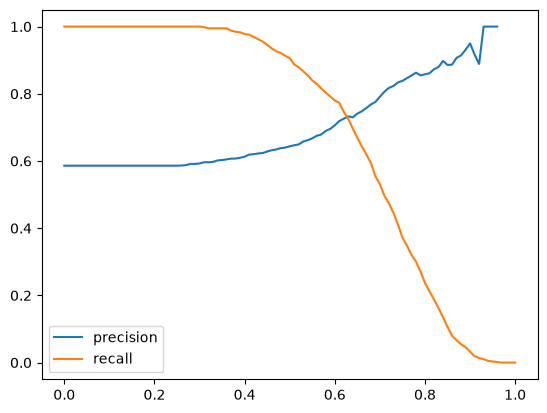

In [87]:
thresholds = np.arange(0,1.01,0.01)

precision = []

recall = []

b = []
for t in thresholds:

    actual_positive = (y_val==1)
    actual_negative = (y_val==0)

    predict_positive = (y_pred>=t)
    predict_negative = (y_pred<t)

    tp = (actual_positive & predict_positive).sum()
    tn = (actual_negative & predict_negative).sum()

    fp = (actual_negative & predict_positive).sum()
    fn = (actual_positive & predict_negative).sum()

    precision.append(tp/(tp+fp))
    recall.append(tp/(tp+fn))
    b.append( (t, (tp/(tp+fp)), (tp/(tp+fn)) ))

plt.plot(thresholds, precision, label='precision')
plt.plot(thresholds, recall, label = 'recall')

plt.legend()



bdf = pd.DataFrame(b, columns=['threshold','precision','recall'])

bdf['diff'] = (bdf['precision']-bdf['recall']).abs()

In [78]:
valid[valid['diff'] == 0]

,threshold,precision,recall,diff


In [89]:
valid = bdf.dropna()
valid = valid[(valid['precision'] > 0) | (valid['recall'] > 0)]

valid.sort_values('diff').head()

,threshold,precision,recall,diff
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079


## Q3  - threshold 0.63

In [91]:
bdf['F1'] = 2 * ((bdf.precision * bdf.recall)/ (bdf.precision+bdf.recall))

In [95]:
bdf.sort_values('F1', ascending=False)

,threshold,precision,recall,diff,F1
41,0.41,0.619048,0.976109,0.357062,0.757616
42,0.42,0.620087,0.969283,0.349196,0.756325
43,0.43,0.622517,0.962457,0.339941,0.756032
45,0.45,0.628118,0.945392,0.317275,0.754768
44,0.44,0.623608,0.955631,0.332023,0.754717
...,...,...,...,...,...
96,0.96,1.000000,0.001706,0.998294,0.003407
97,0.97,NaN,0.000000,NaN,NaN
98,0.98,NaN,0.000000,NaN,NaN
99,0.99,NaN,0.000000,NaN,NaN


# Q4 - highest F1 score is at 0.41

In [98]:
from sklearn.model_selection import KFold

In [99]:
KFold(n_splits=5, shuffle=True, random_state=1)

KFold(n_splits=5, random_state=1, shuffle=True)

In [112]:
def train(df_train,y_train,c=1):
    dv = DictVectorizer(sparse=False)

    train_dict = df_train[categorical + numerical].to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)

    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000)
    model.fit(X_train, y_train)
    return(dv,model)
    
def predict(df,dv,model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)

    y_pred = model.predict_proba(X)[:,1]

    return y_pred    

In [110]:
Kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)
scores=[]
n_splits=5
for train_idx, val_idx  in Kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train=df_train.converted.values
    y_val=df_val.converted.values

    dv,model=train(df_train,y_train)
    y_pred = predict(df_val,dv,model)

    auc=roc_auc_score(y_val,y_pred)
    scores.append(auc)
    print(  '%.3f +- %.3f' % (np.mean(scores), np.std(scores)))

0.731 +- 0.000
0.730 +- 0.000
0.732 +- 0.003
0.734 +- 0.005
0.732 +- 0.007


# Q5 - 0.007 is the largest std across 5 splits

In [113]:

for C in [0.000001, 0.001, 1]:
    Kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)
    scores=[]
    n_splits=5
    for train_idx, val_idx  in Kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train=df_train.converted.values
        y_val=df_val.converted.values

        dv,model=train(df_train,y_train,c=C)
        y_pred = predict(df_val,dv,model)

        auc=roc_auc_score(y_val,y_pred)
        scores.append(auc)
        print(  '%s, %.3f +- %.3f' % ( C ,np.mean(scores), np.std(scores)))

1e-06, 0.594 +- 0.000
1e-06, 0.617 +- 0.023
1e-06, 0.611 +- 0.020
1e-06, 0.618 +- 0.021
1e-06, 0.617 +- 0.019
0.001, 0.750 +- 0.000
0.001, 0.749 +- 0.001
0.001, 0.752 +- 0.005
0.001, 0.754 +- 0.005
0.001, 0.749 +- 0.010
1, 0.731 +- 0.000
1, 0.730 +- 0.000
1, 0.732 +- 0.003
1, 0.734 +- 0.005
1, 0.732 +- 0.007
